# JAAD + Qwen: Pedestrian Crossing Intention Prediction
**Clean implementation notebook for the `yash` branch**  
Paper basis: *Pedestrian Intention Prediction via Vision-Language Foundation Models* (arXiv:2507.04141).

This notebook implements a Qwen-based adaptation using **JAAD only**:
1. Read official JAAD XML annotations and the official train/validation/test video splits.
2. Create samples with 16 observed frames and a 16-frame future prediction horizon.
3. Draw a red bounding box around the target pedestrian in each observed frame.
4. Evaluate hierarchical prompts: role/baseline, physical cues, and descriptive vehicle dynamics.
5. Select prompt variants using the validation split, then evaluate once on the test split.
6. Save predictions and report Accuracy, Precision, Recall, F1, and ROC-AUC.

**Important:** the paper's original VLMs were GPT-family and LLaVA models. Qwen is a replacement, so report this as a Qwen adaptation, not an exact numerical reproduction. The notebook does not use PIE, FU-PIP, or any other dataset.

## Run safely in your own branch
Save this notebook as `notebooks/jaad_qwen_pedestrian_intention.ipynb`. It does not overwrite application code. The JAAD toolkit is cloned separately into `third_party/JAAD`. Make sure `git status` is clean before committing.

## 1. Install dependencies
Run in a GPU runtime if possible. Qwen2.5-VL-3B is the practical starting point; 7B generally needs more GPU memory. For limited VRAM, consider 4-bit quantization in a separate tested environment.

In [1]:
%pip install -U transformers accelerate qwen-vl-utils opencv-python pillow pandas numpy scikit-learn matplotlib seaborn tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 97.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 13.1 MB/s eta 0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled 

## 2. Imports and configuration

In [1]:
from pathlib import Path
import os, sys, subprocess, json, re, random, warnings
from collections import Counter
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Change this to the folder containing JAAD_clips/, annotations/, split_ids/, etc.
JAAD_ROOT = Path(r"./dataset/JAAD")

# Keep all implementation artifacts isolated from existing project files.
ARTIFACT_DIR = Path("./artifacts/jaad_qwen")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
OBSERVED_FRAMES = 16
FUTURE_HORIZON = 16
SAMPLE_STRIDE = 8            # reduce overlap/cost; set to 1 for denser evaluation
MAX_SAMPLES_PER_SPLIT = None # e.g. 100 for a quick smoke test; None for full run
MAX_NEW_TOKENS = 32

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("JAAD root exists:", JAAD_ROOT.exists())

Torch: 2.11.0+cu130
CUDA available: True
JAAD root exists: False


## 3. Get the official JAAD annotation interface
JAAD videos and annotations must be obtained from the official JAAD source and placed under `JAAD_ROOT`. This cell clones only the annotation toolkit into `third_party/JAAD`; it does not modify your existing source files.

In [2]:
JAAD_TOOLKIT = Path("./third_party/JAAD")
JAAD_TOOLKIT.parent.mkdir(parents=True, exist_ok=True)

if not (JAAD_TOOLKIT / "jaad_data.py").exists():
    subprocess.run([
        "git", "clone", "--depth", "1", "--branch", "JAAD_2.0",
        "https://github.com/ykotseruba/JAAD.git", str(JAAD_TOOLKIT)
    ], check=True)

sys.path.insert(0, str(JAAD_TOOLKIT.resolve()))

required_dirs = ["annotations", "annotations_attributes", "annotations_appearance",
                 "annotations_vehicle", "annotations_traffic", "split_ids", "JAAD_clips"]
missing = [d for d in required_dirs if not (JAAD_ROOT / d).exists()]
if missing:
    print("JAAD folder is missing:", missing)
    print("Download JAAD from the official source and place its folders under JAAD_ROOT.")
else:
    print("JAAD folder structure looks present.")

JAAD folder is missing: ['annotations', 'annotations_attributes', 'annotations_appearance', 'annotations_vehicle', 'annotations_traffic', 'split_ids', 'JAAD_clips']
Download JAAD from the official source and place its folders under JAAD_ROOT.


## 4. Parse official JAAD annotations

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/JAAD_clips.zip")
print("Exists:", ZIP_PATH.exists())

if ZIP_PATH.exists():
    print(f"Size: {ZIP_PATH.stat().st_size / (1024**3):.2f} GB")

Exists: True
Size: 2.87 GB


In [8]:
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/JAAD_clips.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("ZIP is valid:", z.testzip() is None)
    print("\nFirst 30 entries:")
    for name in z.namelist()[:30]:
        print(name)

    print("\nTop-level folders:")
    roots = sorted({
        name.split("/")[0]
        for name in z.namelist()
        if name
    })
    print(roots)

ZIP is valid: True

First 30 entries:
JAAD_clips/
JAAD_clips/video_0001.mp4
JAAD_clips/video_0002.mp4
JAAD_clips/video_0003.mp4
JAAD_clips/video_0004.mp4
JAAD_clips/video_0005.mp4
JAAD_clips/video_0006.mp4
JAAD_clips/video_0007.mp4
JAAD_clips/video_0008.mp4
JAAD_clips/video_0009.mp4
JAAD_clips/video_0010.mp4
JAAD_clips/video_0011.mp4
JAAD_clips/video_0012.mp4
JAAD_clips/video_0013.mp4
JAAD_clips/video_0014.mp4
JAAD_clips/video_0015.mp4
JAAD_clips/video_0016.mp4
JAAD_clips/video_0017.mp4
JAAD_clips/video_0018.mp4
JAAD_clips/video_0019.mp4
JAAD_clips/video_0020.mp4
JAAD_clips/video_0021.mp4
JAAD_clips/video_0022.mp4
JAAD_clips/video_0023.mp4
JAAD_clips/video_0024.mp4
JAAD_clips/video_0025.mp4
JAAD_clips/video_0026.mp4
JAAD_clips/video_0027.mp4
JAAD_clips/video_0028.mp4
JAAD_clips/video_0029.mp4

Top-level folders:
['JAAD_clips']


In [11]:
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/JAAD_clips.zip")
JAAD_ROOT = Path("/content/dataset/JAAD")

JAAD_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall("/content/dataset")

print("JAAD clips folder exists:",
      Path("/content/dataset/JAAD_clips").exists())

print("Number of video files:",
      len(list(Path("/content/dataset/JAAD_clips").glob("*.mp4"))))

JAAD clips folder exists: True
Number of video files: 346


In [12]:
from pathlib import Path

for root in [Path("/content"), Path("/content/drive/MyDrive")]:
    print(f"\nChecking: {root}")
    for name in [
        "annotations",
        "annotations_attributes",
        "annotations_appearance",
        "annotations_vehicle",
        "annotations_traffic",
        "split_ids",
        "JAAD",
    ]:
        matches = list(root.glob(f"**/{name}"))
        for path in matches[:5]:
            print(path)


Checking: /content
/content/third_party/JAAD/annotations
/content/third_party/JAAD/annotations_attributes
/content/third_party/JAAD/annotations_appearance
/content/third_party/JAAD/annotations_vehicle
/content/third_party/JAAD/annotations_traffic
/content/third_party/JAAD/split_ids
/content/third_party/JAAD
/content/dataset/JAAD

Checking: /content/drive/MyDrive


In [13]:
from pathlib import Path

JAAD_REPO = Path("/content/third_party/JAAD")
JAAD_ROOT = JAAD_REPO
CLIPS_DIR = Path("/content/dataset/JAAD_clips")

required = [
    "annotations",
    "annotations_attributes",
    "annotations_appearance",
    "annotations_vehicle",
    "annotations_traffic",
    "split_ids",
]

for folder in required:
    path = JAAD_ROOT / folder
    print(f"{'OK' if path.exists() else 'MISSING'}: {path}")

print(f"\nVideo clips: {len(list(CLIPS_DIR.glob('*.mp4')))}")

OK: /content/third_party/JAAD/annotations
OK: /content/third_party/JAAD/annotations_attributes
OK: /content/third_party/JAAD/annotations_appearance
OK: /content/third_party/JAAD/annotations_vehicle
OK: /content/third_party/JAAD/annotations_traffic
OK: /content/third_party/JAAD/split_ids

Video clips: 346


In [14]:
from pathlib import Path

split_dir = Path("/content/third_party/JAAD/split_ids")

for path in split_dir.rglob("*"):
    if path.is_file():
        print(path)

/content/third_party/JAAD/split_ids/high_visibility/val.txt
/content/third_party/JAAD/split_ids/high_visibility/test.txt
/content/third_party/JAAD/split_ids/high_visibility/train.txt
/content/third_party/JAAD/split_ids/default/val.txt
/content/third_party/JAAD/split_ids/default/test.txt
/content/third_party/JAAD/split_ids/default/train.txt
/content/third_party/JAAD/split_ids/all_videos/val.txt
/content/third_party/JAAD/split_ids/all_videos/test.txt
/content/third_party/JAAD/split_ids/all_videos/train.txt


In [15]:
from pathlib import Path

clips_dir = Path("/content/dataset/JAAD_clips")

print("First 10 videos:")
for path in sorted(clips_dir.glob("*.mp4"))[:10]:
    print(path.name)

First 10 videos:
video_0001.mp4
video_0002.mp4
video_0003.mp4
video_0004.mp4
video_0005.mp4
video_0006.mp4
video_0007.mp4
video_0008.mp4
video_0009.mp4
video_0010.mp4


In [16]:
from pathlib import Path

REPO = Path("/content/third_party/JAAD")

# 1. Inspect the default split files
for split in ["train", "val", "test"]:
    path = REPO / "split_ids" / "default" / f"{split}.txt"
    lines = [
        line.strip()
        for line in path.read_text().splitlines()
        if line.strip()
    ]

    print(f"\n{split.upper()}: {len(lines)} entries")
    print("First 5:", lines[:5])

# 2. Inspect annotation files
for folder in [
    "annotations",
    "annotations_attributes",
    "annotations_appearance",
    "annotations_vehicle",
    "annotations_traffic",
]:
    path = REPO / folder
    files = sorted(p.name for p in path.iterdir() if p.is_file())

    print(f"\n{folder}: {len(files)} files")
    print("First 5:", files[:5])

# 3. Verify video IDs
clips = Path("/content/dataset/JAAD_clips")
print("\nFirst 5 video stems:",
      [p.stem for p in sorted(clips.glob("*.mp4"))[:5]])


TRAIN: 177 entries
First 5: ['video_0001', 'video_0003', 'video_0004', 'video_0007', 'video_0008']

VAL: 29 entries
First 5: ['video_0006', 'video_0021', 'video_0040', 'video_0044', 'video_0072']

TEST: 117 entries
First 5: ['video_0005', 'video_0015', 'video_0016', 'video_0017', 'video_0028']

annotations: 346 files
First 5: ['video_0001.xml', 'video_0002.xml', 'video_0003.xml', 'video_0004.xml', 'video_0005.xml']

annotations_attributes: 346 files
First 5: ['video_0001_attributes.xml', 'video_0002_attributes.xml', 'video_0003_attributes.xml', 'video_0004_attributes.xml', 'video_0005_attributes.xml']

annotations_appearance: 346 files
First 5: ['video_0001_appearance.xml', 'video_0002_appearance.xml', 'video_0003_appearance.xml', 'video_0004_appearance.xml', 'video_0005_appearance.xml']

annotations_vehicle: 346 files
First 5: ['video_0001_vehicle.xml', 'video_0002_vehicle.xml', 'video_0003_vehicle.xml', 'video_0004_vehicle.xml', 'video_0005_vehicle.xml']

annotations_traffic: 346 fi

In [17]:
import xml.etree.ElementTree as ET
from pathlib import Path
import sys

REPO = Path("/content/third_party/JAAD")

# 1. Inspect the XML structure
xml_path = REPO / "annotations" / "video_0001.xml"
root = ET.parse(xml_path).getroot()

print("XML root:", root.tag)
print("Root attributes:", root.attrib)

for track in root.findall("./track")[:3]:
    print("\nTrack attributes:", track.attrib)
    box = track.find("./box")
    if box is not None:
        print("First box attributes:", box.attrib)
        for attr in box.findall("./attribute"):
            print(f"  {attr.get('name')}: {attr.text}")

# 2. Inspect pedestrian-level attributes
attr_path = REPO / "annotations_attributes" / "video_0001_attributes.xml"
attr_root = ET.parse(attr_path).getroot()

print("\nAttributes XML root:", attr_root.tag)
for pedestrian in list(attr_root)[:3]:
    print(pedestrian.tag, pedestrian.attrib)

# 3. Check the Python interface
sys.path.insert(0, str(REPO))
import jaad_data

print("\nJAAD-related classes and functions:")
print([name for name in dir(jaad_data) if "JAAD" in name])

if hasattr(jaad_data, "JAAD"):
    print("\nJAAD methods:")
    print([name for name in dir(jaad_data.JAAD) if not name.startswith("__")])

XML root: annotations
Root attributes: {}

Track attributes: {'label': 'pedestrian'}
First box attributes: {'frame': '0', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '533.0', 'xtl': '465.0', 'ybr': '848.0', 'ytl': '730.0'}
  id: 0_1_3b
  old_id: pedestrian1
  look: not-looking
  reaction: __undefined__
  action: standing
  cross: not-crossing
  hand_gesture: __undefined__
  occlusion: none
  nod: __undefined__

Track attributes: {'label': 'ped'}
First box attributes: {'frame': '379', 'keyframe': '1', 'occluded': '1', 'outside': '0', 'xbr': '186.0', 'xtl': '150.0', 'ybr': '796.0', 'ytl': '684.0'}
  id: 0_1_2
  old_id: ped2
  occlusion: full

Track attributes: {'label': 'pedestrian'}
First box attributes: {'frame': '0', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '1486.0', 'xtl': '1398.0', 'ybr': '892.0', 'ytl': '654.0'}
  id: 0_1_2b
  old_id: pedestrian2
  look: not-looking
  reaction: __undefined__
  action: walking
  cross: not-crossing
  hand_gesture: __unde

In [18]:
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

REPO = Path("/content/third_party/JAAD")

cross_counts = Counter()
action_counts = Counter()
track_counts = Counter()
crossing_metadata = Counter()
frames_per_video = []

for xml_path in sorted((REPO / "annotations").glob("*.xml")):
    root = ET.parse(xml_path).getroot()
    max_frame = -1

    for track in root.findall(".//track"):
        track_type = track.get("label", "unknown")
        track_counts[track_type] += 1

        # Focus on pedestrian tracks with frame-level boxes
        if track_type not in ("pedestrian", "ped"):
            continue

        for box in track.findall("./box"):
            frame = int(box.get("frame", -1))
            max_frame = max(max_frame, frame)

            if box.get("outside") == "1":
                continue

            for attr in box.findall("./attribute"):
                name = attr.get("name")
                value = (attr.text or "").strip()

                if name == "cross":
                    cross_counts[value] += 1
                elif name == "action":
                    action_counts[value] += 1

    frames_per_video.append((xml_path.stem, max_frame + 1))

# Pedestrian-level crossing metadata
for xml_path in sorted((REPO / "annotations_attributes").glob("*_attributes.xml")):
    root = ET.parse(xml_path).getroot()
    for ped in root.findall(".//pedestrian"):
        crossing_metadata[ped.get("crossing", "missing")] += 1

print("Track types:", track_counts)
print("\nFrame-level cross labels:", cross_counts)
print("\nFrame-level actions:", action_counts)
print("\nPedestrian crossing metadata:", crossing_metadata)
print("\nVideos inspected:", len(frames_per_video))
print("Example frame counts:", frames_per_video[:10])

Track types: Counter({'ped': 2017, 'pedestrian': 686, 'people': 83})

Frame-level cross labels: Counter({'crossing': 75047, 'not-crossing': 57653})

Frame-level actions: Counter({'walking': 113284, 'standing': 19416})

Pedestrian crossing metadata: Counter({'1': 495, '-1': 100, '0': 91})

Videos inspected: 346
Example frame counts: [('video_0001', 600), ('video_0002', 210), ('video_0003', 186), ('video_0004', 176), ('video_0005', 240), ('video_0006', 330), ('video_0007', 120), ('video_0008', 150), ('video_0009', 97), ('video_0010', 90)]


In [19]:

import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
import pandas as pd

REPO = Path("/content/third_party/JAAD")
CLIPS_DIR = Path("/content/dataset/JAAD_clips")
OUTPUT_DIR = Path("/content/jaad_qwen_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OBS_FRAMES = 16
FUTURE_FRAMES = 16
SAMPLE_STRIDE = 4  # Reduce highly overlapping examples

# Read official video splits
splits = {}
for split in ["train", "val", "test"]:
    split_file = REPO / "split_ids" / "default" / f"{split}.txt"
    splits[split] = {
        line.strip()
        for line in split_file.read_text().splitlines()
        if line.strip()
    }

# Confirm that video splits do not overlap
assert not (splits["train"] & splits["val"])
assert not (splits["train"] & splits["test"])
assert not (splits["val"] & splits["test"])

records = []
stats = Counter()

for split_name, video_ids in splits.items():
    for video_id in sorted(video_ids):
        xml_path = REPO / "annotations" / f"{video_id}.xml"
        video_path = CLIPS_DIR / f"{video_id}.mp4"

        if not xml_path.exists() or not video_path.exists():
            stats["missing_video_or_xml"] += 1
            continue

        root = ET.parse(xml_path).getroot()

        for track_idx, track in enumerate(root.findall("./track")):
            if track.get("label") not in {"pedestrian", "ped"}:
                continue

            # frame -> annotation for this pedestrian track
            frame_map = {}

            for box in track.findall("./box"):
                if box.get("outside") == "1":
                    continue

                try:
                    frame = int(box.get("frame"))
                except (TypeError, ValueError):
                    continue

                attrs = {
                    a.get("name"): (a.text or "").strip()
                    for a in box.findall("./attribute")
                }

                cross = attrs.get("cross", "")
                if cross not in {"crossing", "not-crossing"}:
                    continue

                try:
                    bbox = [
                        float(box.get("xtl")),
                        float(box.get("ytl")),
                        float(box.get("xbr")),
                        float(box.get("ybr")),
                    ]
                except (TypeError, ValueError):
                    continue

                frame_map[frame] = {
                    "cross": cross,
                    "bbox": bbox,
                }

            if not frame_map:
                continue

            # Require contiguous, labelled observations and future frames.
            min_anchor = OBS_FRAMES - 1
            max_anchor = max(frame_map) - FUTURE_FRAMES

            for anchor in range(min_anchor, max_anchor + 1, SAMPLE_STRIDE):
                obs_ids = list(
                    range(anchor - OBS_FRAMES + 1, anchor + 1)
                )
                future_ids = list(
                    range(anchor + 1, anchor + FUTURE_FRAMES + 1)
                )

                required_ids = obs_ids + future_ids

                if any(f not in frame_map for f in required_ids):
                    stats["incomplete_windows"] += 1
                    continue

                obs_labels = [
                    frame_map[f]["cross"] for f in obs_ids
                ]
                future_labels = [
                    frame_map[f]["cross"] for f in future_ids
                ]

                # Avoid examples where crossing is already visible
                # in the observed window.
                if any(label == "crossing" for label in obs_labels):
                    stats["already_crossing_in_observation"] += 1
                    continue

                if not all(
                    label in {"crossing", "not-crossing"}
                    for label in future_labels
                ):
                    stats["unknown_future_label"] += 1
                    continue

                # Only label a negative if all future frames are
                # explicitly labelled not-crossing.
                if all(label == "not-crossing" for label in future_labels):
                    target = 0
                elif "crossing" in future_labels:
                    target = 1
                else:
                    continue

                records.append({
                    "video_id": video_id,
                    "split": split_name,
                    "track_key": f"{video_id}_track_{track_idx}",
                    "anchor_frame": anchor,
                    "obs_frames": obs_ids,
                    "obs_boxes": [
                        frame_map[f]["bbox"] for f in obs_ids
                    ],
                    "label": target,
                })

                stats[f"{split_name}_examples"] += 1
                stats[f"{split_name}_positive" if target == 1
                      else f"{split_name}_negative"] += 1

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError(
        "No examples were generated. We need to inspect the annotation "
        "frame coverage and revise the window-building logic."
    )

df.to_json(
    OUTPUT_DIR / "jaad_manifest.jsonl",
    orient="records",
    lines=True,
)

print("Examples generated:", len(df))
print("\nCounts by split and label:")
print(pd.crosstab(df["split"], df["label"]).reindex(
    ["train", "val", "test"], fill_value=0
))

print("\nBuild diagnostics:")
for key, value in sorted(stats.items()):
    print(f"{key}: {value}")

print("\nSaved manifest:", OUTPUT_DIR / "jaad_manifest.jsonl")
print("\nExample record:")
print(df.iloc[0][[
    "video_id", "split", "track_key",
    "anchor_frame", "label"
]].to_dict())


Examples generated: 10563

Counts by split and label:
label     0    1
split           
train  4564  547
val     813   88
test   4145  406

Build diagnostics:
already_crossing_in_observation: 15667
incomplete_windows: 3671
test_examples: 4551
test_negative: 4145
test_positive: 406
train_examples: 5111
train_negative: 4564
train_positive: 547
val_examples: 901
val_negative: 813
val_positive: 88

Saved manifest: /content/jaad_qwen_artifacts/jaad_manifest.jsonl

Example record:
{'video_id': 'video_0001', 'split': 'train', 'track_key': 'video_0001_track_0', 'anchor_frame': 15, 'label': 0}


GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.64

Sample video: video_0001.mp4
FPS: 29.97002997002997
Video dimensions: 1920 x 1080
Video frame count: 600
Observation frames: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


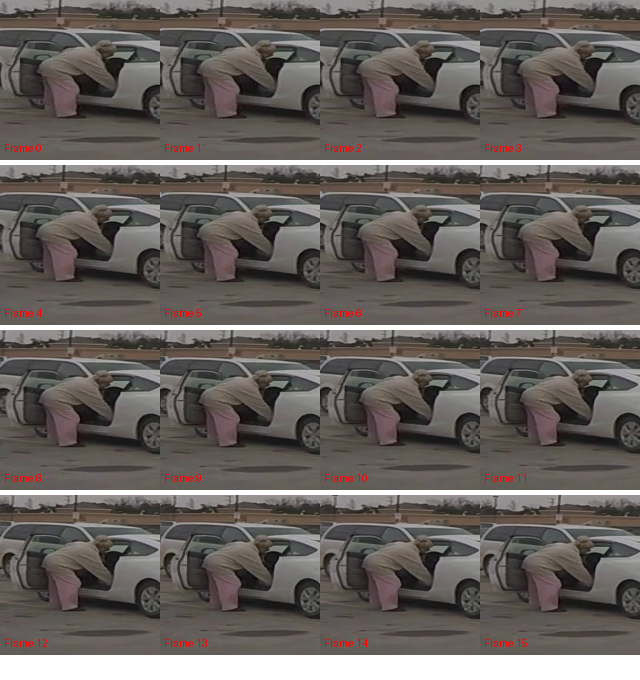


Valid crops: 16/16


In [20]:

import cv2
import json
import torch
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

CLIPS_DIR = Path("/content/dataset/JAAD_clips")
MANIFEST = Path("/content/jaad_qwen_artifacts/jaad_manifest.jsonl")

df = pd.read_json(MANIFEST, lines=True)
sample = df.iloc[0]

video_path = CLIPS_DIR / f"{sample['video_id']}.mp4"
cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

print("\nSample video:", video_path.name)
print("FPS:", fps)
print("Video dimensions:", width, "x", height)
print("Video frame count:", total_frames)
print("Observation frames:", sample["obs_frames"])

# Make a 4x4 contact sheet of the annotated pedestrian crops
frames = sample["obs_frames"]
boxes = sample["obs_boxes"]
thumbs = []

for frame_no, box in zip(frames, boxes):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_no))
    ok, frame = cap.read()

    if not ok:
        print("Could not read frame:", frame_no)
        continue

    x1, y1, x2, y2 = map(float, box)

    # Expand the bounding box to preserve some surrounding context
    bw, bh = x2 - x1, y2 - y1
    x1 = max(0, int(x1 - 0.5 * bw))
    y1 = max(0, int(y1 - 0.5 * bh))
    x2 = min(width, int(x2 + 0.5 * bw))
    y2 = min(height, int(y2 + 0.5 * bh))

    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        print("Invalid crop at frame:", frame_no)
        continue

    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    thumbs.append(Image.fromarray(crop).resize((160, 160)))

cap.release()

sheet = Image.new("RGB", (640, 680), "white")
draw = ImageDraw.Draw(sheet)

for i, thumb in enumerate(thumbs):
    x = (i % 4) * 160
    y = (i // 4) * 165
    sheet.paste(thumb, (x, y))
    draw.text((x + 4, y + 142), f"Frame {frames[i]}", fill="red")

display(sheet)
print(f"\nValid crops: {len(thumbs)}/16")


In [21]:

import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    attn_implementation="sdpa",
)

model.eval()

print("Model loaded:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print("Allocated GPU memory (GB):",
      round(torch.cuda.memory_allocated() / 1e9, 2))


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-VL-3B-Instruct
GPU: Tesla T4
Allocated GPU memory (GB): 7.51


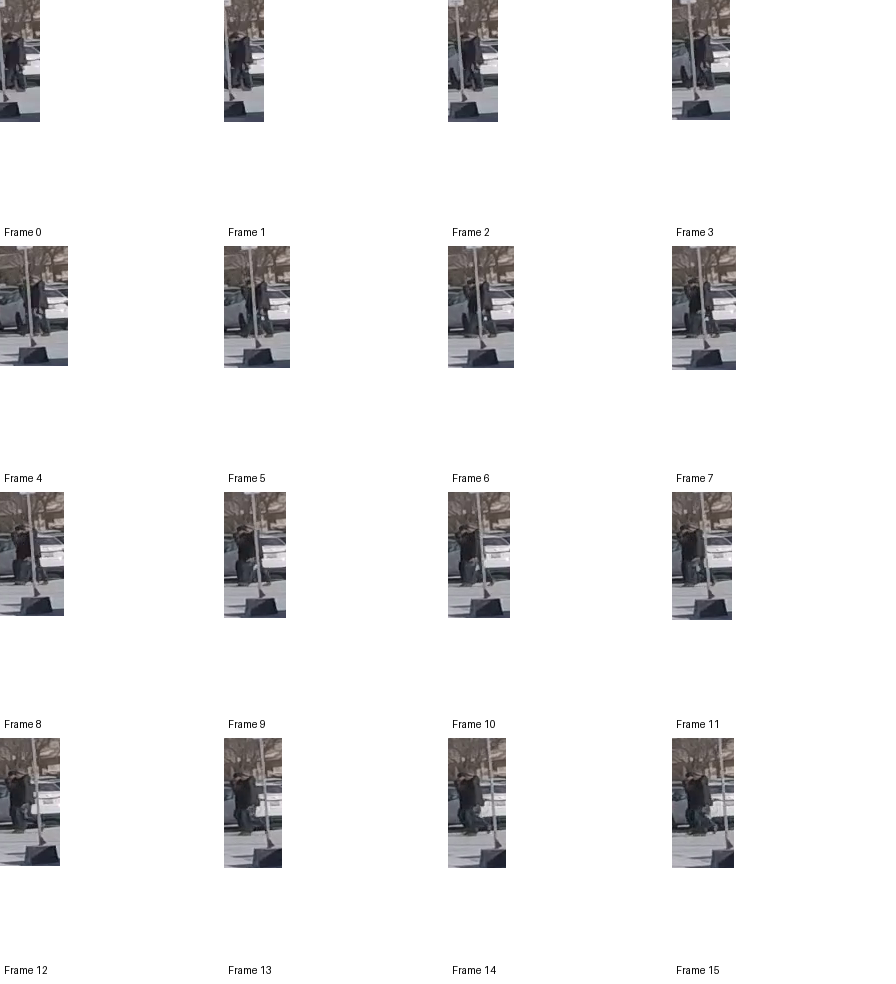

Video: video_0006
Anchor frame: 15
Ground-truth label: 0
Qwen response: ```json
{
  "prediction": 0,
  "reason": "The pedestrian appears to be walking and is not near any vehicles, indicating no immediate crossing intention."
}
```


In [22]:

import cv2
import json
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

CLIPS_DIR = Path("/content/dataset/JAAD_clips")
MANIFEST = Path("/content/jaad_qwen_artifacts/jaad_manifest.jsonl")

df = pd.read_json(MANIFEST, lines=True)
sample = df[df["split"] == "val"].iloc[0]

def make_contact_sheet(sample, cell_size=224):
    video_path = CLIPS_DIR / f"{sample['video_id']}.mp4"
    cap = cv2.VideoCapture(str(video_path))

    sheet = Image.new("RGB", (cell_size * 4, (cell_size + 22) * 4), "white")
    draw = ImageDraw.Draw(sheet)

    try:
        for i, (frame_no, box) in enumerate(
            zip(sample["obs_frames"], sample["obs_boxes"])
        ):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_no))
            ok, frame = cap.read()

            if not ok:
                raise RuntimeError(
                    f"Cannot read {sample['video_id']} frame {frame_no}"
                )

            height, width = frame.shape[:2]
            x1, y1, x2, y2 = map(float, box)
            bw, bh = x2 - x1, y2 - y1

            # Preserve some context around the annotated pedestrian
            x1 = max(0, int(x1 - 0.5 * bw))
            y1 = max(0, int(y1 - 0.5 * bh))
            x2 = min(width, int(x2 + 0.5 * bw))
            y2 = min(height, int(y2 + 0.5 * bh))

            crop = frame[y1:y2, x1:x2]
            if crop.size == 0:
                raise RuntimeError("Empty pedestrian crop")

            crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
            image = Image.fromarray(crop)
            image.thumbnail((cell_size, cell_size))

            col, row = i % 4, i // 4
            x, y = col * cell_size, row * (cell_size + 22)
            sheet.paste(image, (x, y))
            draw.text((x + 4, y + cell_size + 2),
                      f"Frame {frame_no}", fill="black")
    finally:
        cap.release()

    return sheet

contact_sheet = make_contact_sheet(sample)
display(contact_sheet)

prompt = """
You are evaluating pedestrian crossing intention.

The image is a contact sheet of 16 chronological video frames.
The frames show one annotated pedestrian over time.

Predict whether this pedestrian will begin crossing within the next
16 video frames after the observation ends.

Use only visual evidence in the image. Do not infer a crossing merely
because the pedestrian is walking or near a vehicle.

Return exactly one JSON object:
{"prediction": 0, "reason": "brief visual explanation"}

Use prediction 1 if crossing is likely to begin within the horizon.
Use prediction 0 otherwise. If evidence is ambiguous, choose 0.
"""

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": contact_sheet},
        {"type": "text", "text": prompt},
    ],
}]

inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
)

inputs = {
    key: value.to(model.device) if hasattr(value, "to") else value
    for key, value in inputs.items()
}

with torch.inference_mode():
    generated = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False,
    )

new_tokens = generated[:, inputs["input_ids"].shape[1]:]
response = processor.batch_decode(
    new_tokens,
    skip_special_tokens=True,
)[0]

print("Video:", sample["video_id"])
print("Anchor frame:", sample["anchor_frame"])
print("Ground-truth label:", int(sample["label"]))
print("Qwen response:", response)


In [23]:

import re
import json
import torch
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

MANIFEST = "/content/jaad_qwen_artifacts/jaad_manifest.jsonl"
df = pd.read_json(MANIFEST, lines=True)

# Reproducible pilot subset; validation only
val_df = df[df["split"] == "val"].sample(
    n=min(50, len(df[df["split"] == "val"])),
    random_state=42,
).reset_index(drop=True)

def predict_qwen(sample):
    contact_sheet = make_contact_sheet(sample)

    prompt = """
You are predicting pedestrian crossing intention from chronological video frames.
The image is a contact sheet of 16 observed frames of one pedestrian.
Predict whether that pedestrian will begin crossing within the next 16 frames.
Use visual evidence only. Do not assume that walking automatically means crossing.
Return exactly one JSON object:
{"prediction": 0, "reason": "brief explanation"}
Use 1 if crossing begins within the horizon, otherwise 0.
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": contact_sheet},
            {"type": "text", "text": prompt},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = {
        k: v.to(model.device) if hasattr(v, "to") else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
        )

    new_tokens = output[:, inputs["input_ids"].shape[1]:]
    text = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0]

    # Parse prediction field, tolerating Markdown code fences
    match = re.search(
        r'"prediction"\s*:\s*([01])',
        text,
        flags=re.IGNORECASE,
    )

    pred = int(match.group(1)) if match else None
    return pred, text

results = []

for i, sample in val_df.iterrows():
    try:
        pred, raw = predict_qwen(sample)
        results.append({
            "video_id": sample["video_id"],
            "track_key": sample["track_key"],
            "anchor_frame": int(sample["anchor_frame"]),
            "y_true": int(sample["label"]),
            "y_pred": pred,
            "raw_response": raw,
        })
    except Exception as e:
        results.append({
            "video_id": sample["video_id"],
            "track_key": sample["track_key"],
            "anchor_frame": int(sample["anchor_frame"]),
            "y_true": int(sample["label"]),
            "y_pred": None,
            "raw_response": f"ERROR: {e}",
        })

    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/{len(val_df)}")

res = pd.DataFrame(results)
valid = res.dropna(subset=["y_pred"]).copy()
valid["y_pred"] = valid["y_pred"].astype(int)

print("\nTotal pilot examples:", len(res))
print("Valid predictions:", len(valid))
print("Failed predictions:", len(res) - len(valid))

if len(valid) and valid["y_true"].nunique() == 2:
    print("\nAccuracy:", round(accuracy_score(valid.y_true, valid.y_pred), 4))
    print("Precision:", round(precision_score(
        valid.y_true, valid.y_pred, zero_division=0
    ), 4))
    print("Recall:", round(recall_score(
        valid.y_true, valid.y_pred, zero_division=0
    ), 4))
    print("F1:", round(f1_score(
        valid.y_true, valid.y_pred, zero_division=0
    ), 4))
    print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(valid.y_true, valid.y_pred, labels=[0, 1]))
    print("\nClassification report:")
    print(classification_report(
        valid.y_true, valid.y_pred, zero_division=0
    ))
else:
    print("Not enough valid predictions or only one class in this subset.")

out_path = "/content/jaad_qwen_artifacts/qwen_val_pilot50.csv"
res.to_csv(out_path, index=False)
print("\nSaved:", out_path)


Completed 10/50
Completed 20/50
Completed 30/50
Completed 40/50
Completed 50/50

Total pilot examples: 50
Valid predictions: 50
Failed predictions: 0

Accuracy: 0.92
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion matrix [[TN, FP], [FN, TP]]:
[[46  0]
 [ 4  0]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        46
           1       0.00      0.00      0.00         4

    accuracy                           0.92        50
   macro avg       0.46      0.50      0.48        50
weighted avg       0.85      0.92      0.88        50


Saved: /content/jaad_qwen_artifacts/qwen_val_pilot50.csv


In [24]:

import pandas as pd

pilot_path = "/content/jaad_qwen_artifacts/qwen_val_pilot50.csv"
pilot = pd.read_csv(pilot_path)

print("Prediction distribution:")
print(pilot["y_pred"].value_counts(dropna=False))

print("\nGround-truth distribution:")
print(pilot["y_true"].value_counts(dropna=False))

print("\nRaw responses for the four positive examples:")
positive_misses = pilot[
    (pilot["y_true"] == 1) & (pilot["y_pred"] == 0)
]

for _, row in positive_misses.iterrows():
    print("\nVideo:", row["video_id"])
    print("Track:", row["track_key"])
    print("Anchor frame:", row["anchor_frame"])
    print("Response:", row["raw_response"])


Prediction distribution:
y_pred
0    50
Name: count, dtype: int64

Ground-truth distribution:
y_true
0    46
1     4
Name: count, dtype: int64

Raw responses for the four positive examples:

Video: video_0172
Track: video_0172_track_1
Anchor frame: 111
Response: ```json
{
  "prediction": 0,
  "reason": "The pedestrian is walking in a straight line without any indication of turning or stopping to cross."
}
```

Video: video_0089
Track: video_0089_track_2
Anchor frame: 231
Response: ```json
{
  "prediction": 0,
  "reason": "The pedestrian appears to be walking in a straight line without any indication of preparing to cross the street."
}
```

Video: video_0226
Track: video_0226_track_7
Anchor frame: 155
Response: ```json
{
  "prediction": 0,
  "reason": "The pedestrian is consistently walking in the same direction without any indication of preparing to cross the street."
}
```

Video: video_0226
Track: video_0226_track_7
Anchor frame: 163
Response: ```json
{
  "prediction": 0,
  "reason"

Video: video_0044 | Track: video_0044_track_0 | Anchor: 63 | Label: 1


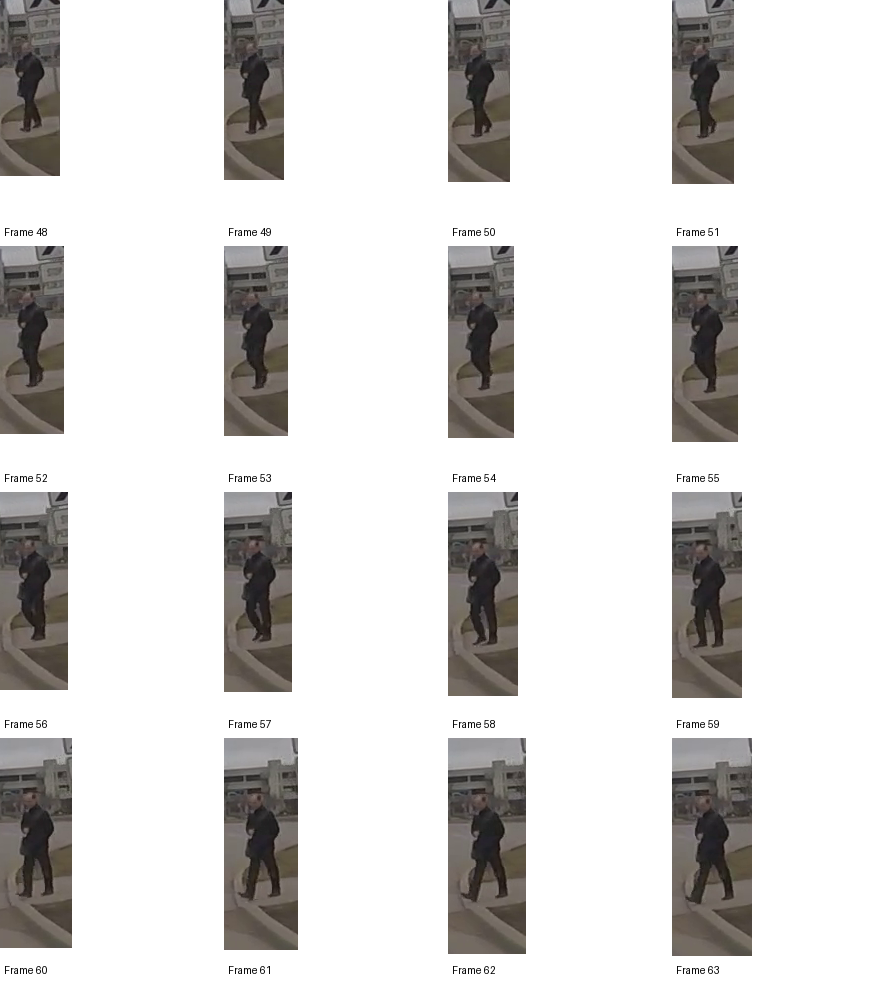

Video: video_0006 | Track: video_0006_track_11 | Anchor: 71 | Label: 1


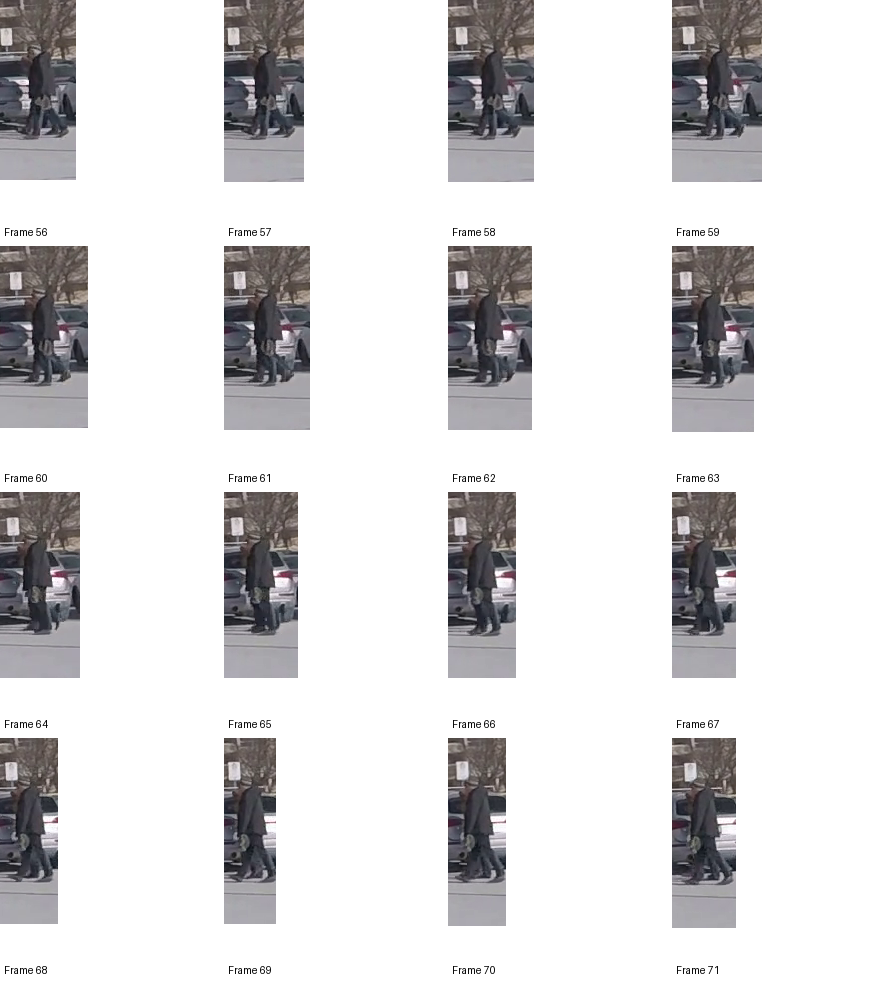

Video: video_0274 | Track: video_0274_track_0 | Anchor: 127 | Label: 1


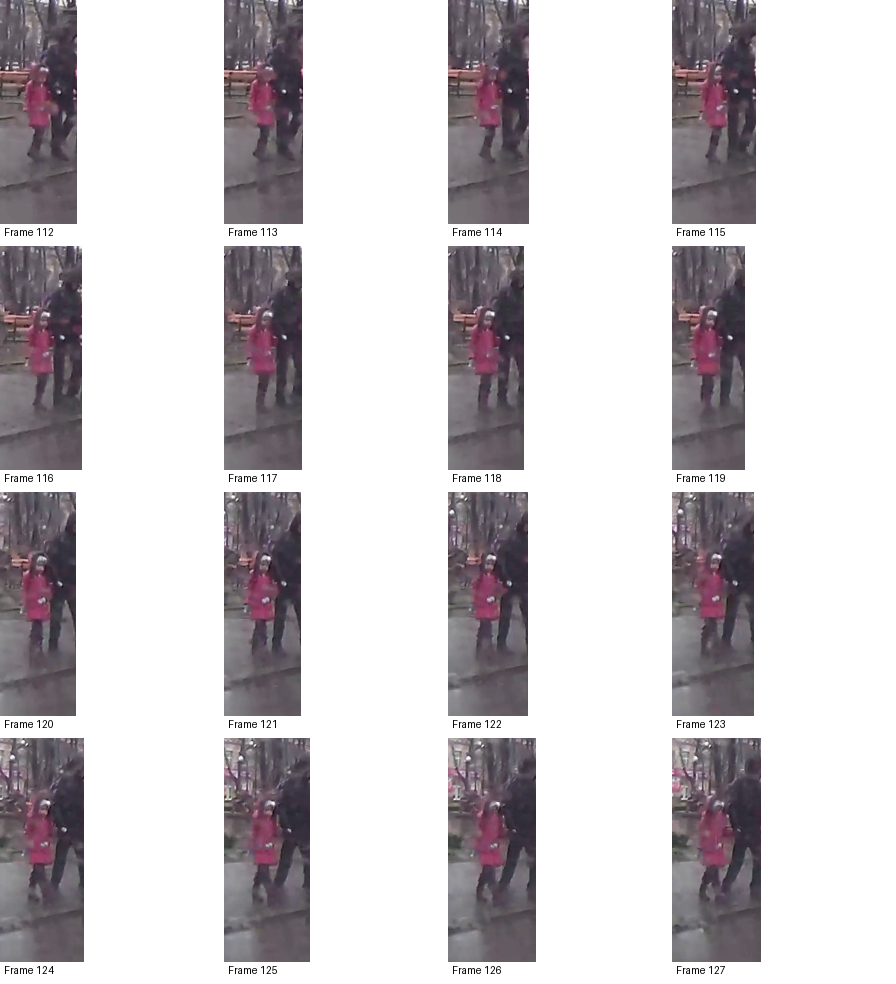

Video: video_0274 | Track: video_0274_track_10 | Anchor: 139 | Label: 1


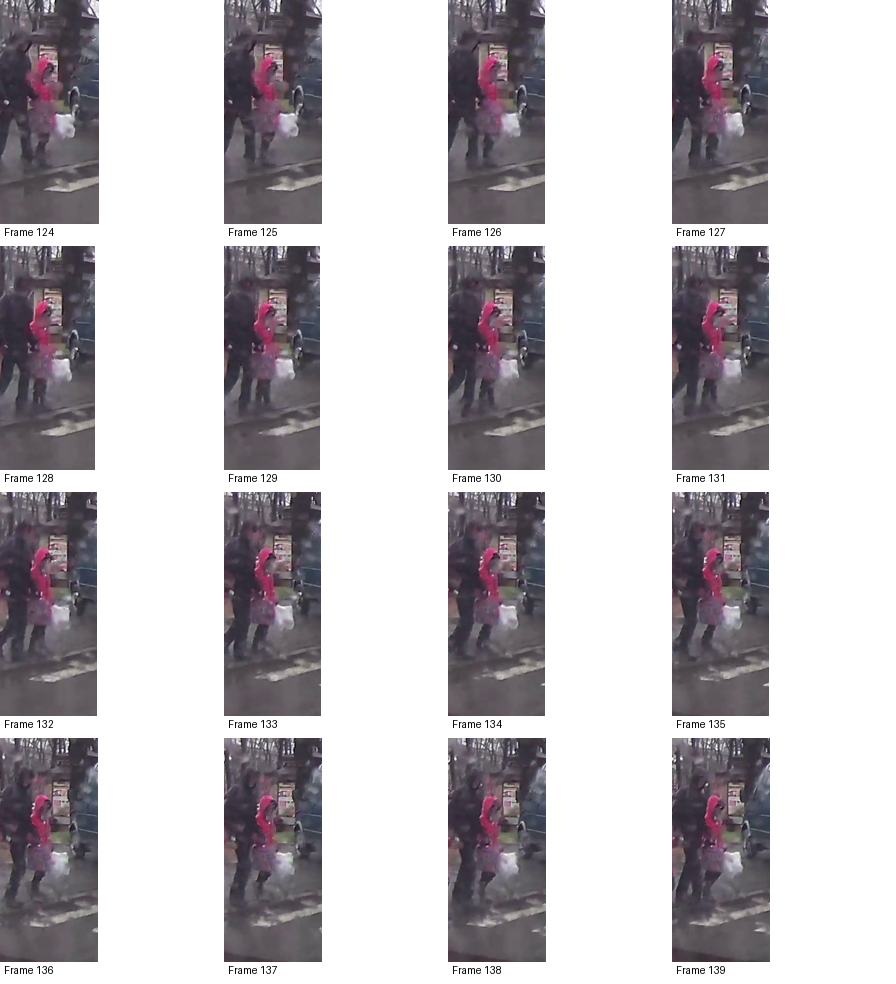

In [25]:

from IPython.display import display
import pandas as pd

df = pd.read_json(
    "/content/jaad_qwen_artifacts/jaad_manifest.jsonl",
    lines=True,
)

positive_val = df[
    (df["split"] == "val") & (df["label"] == 1)
].sample(
    n=min(4, len(df[(df["split"] == "val") & (df["label"] == 1)])),
    random_state=17,
)

for _, sample in positive_val.iterrows():
    print(
        f"Video: {sample['video_id']} | "
        f"Track: {sample['track_key']} | "
        f"Anchor: {sample['anchor_frame']} | "
        f"Label: {sample['label']}"
    )
    display(make_contact_sheet(sample))


video_0006 video_0006_track_0 67


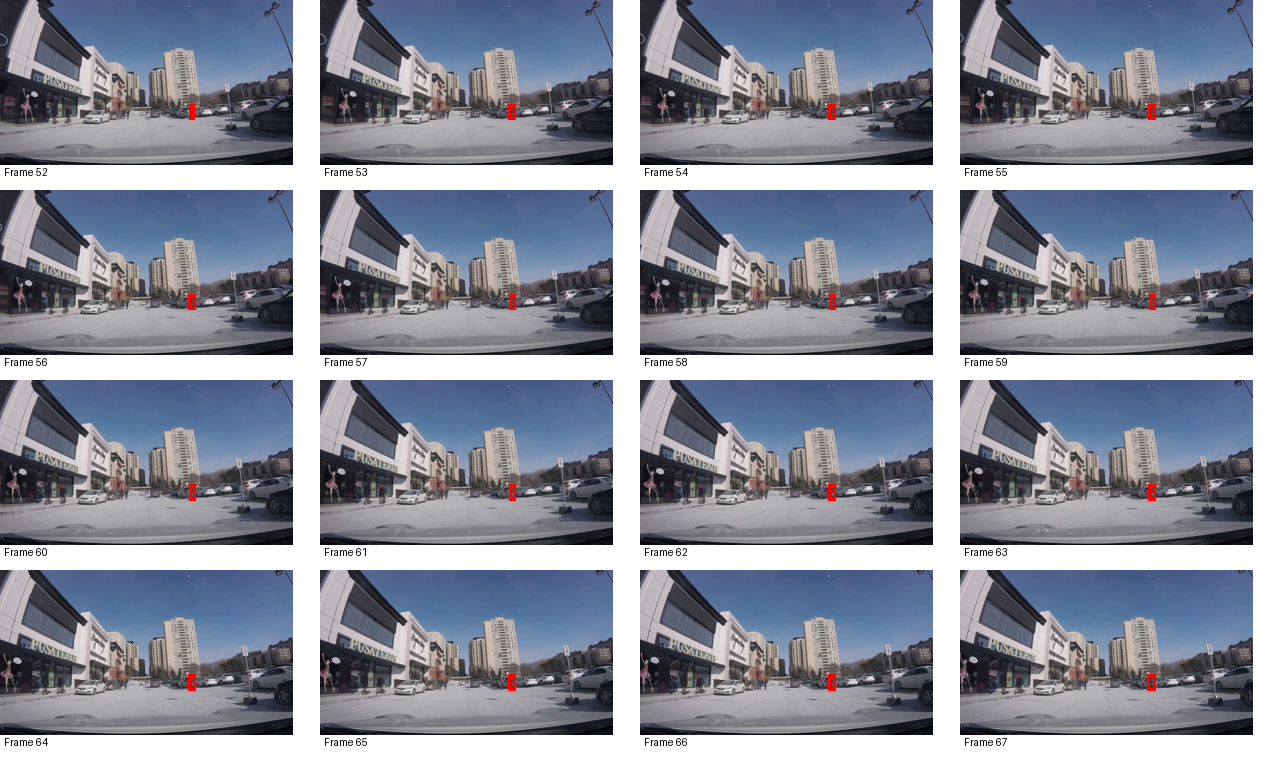

In [26]:

import cv2
from PIL import Image, ImageDraw
from IPython.display import display

def make_scene_contact_sheet(sample, cell_size=320):
    video_path = CLIPS_DIR / f"{sample['video_id']}.mp4"
    cap = cv2.VideoCapture(str(video_path))

    sheet = Image.new("RGB", (cell_size * 4, 4 * 190), "white")
    draw = ImageDraw.Draw(sheet)

    try:
        for i, (frame_no, box) in enumerate(
            zip(sample["obs_frames"], sample["obs_boxes"])
        ):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_no))
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"Cannot read frame {frame_no}")

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            scene = Image.fromarray(frame)
            scene.thumbnail((cell_size, 165))

            # Draw target pedestrian bounding box in original coordinates
            x1, y1, x2, y2 = map(float, box)
            scale = min(cell_size / frame.shape[1], 165 / frame.shape[0])
            draw_box = (
                x1 * scale, y1 * scale,
                x2 * scale, y2 * scale
            )

            scene_draw = ImageDraw.Draw(scene)
            scene_draw.rectangle(draw_box, outline="red", width=3)

            col, row = i % 4, i // 4
            x, y = col * cell_size, row * 190
            sheet.paste(scene, (x, y))
            draw.text((x + 4, y + 166), f"Frame {frame_no}", fill="black")
    finally:
        cap.release()

    return sheet

# Inspect one positive validation example first
sample = df[
    (df["split"] == "val") & (df["label"] == 1)
].iloc[0]

print(sample["video_id"], sample["track_key"], sample["anchor_frame"])
display(make_scene_contact_sheet(sample))


In [27]:

import re
import pandas as pd
import torch
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

val = df[df["split"] == "val"]

n_each = min(25, int((val["label"] == 1).sum()),
             int((val["label"] == 0).sum()))

balanced = pd.concat([
    val[val["label"] == 0].sample(n=n_each, random_state=42),
    val[val["label"] == 1].sample(n=n_each, random_state=42),
]).sample(frac=1, random_state=42).reset_index(drop=True)

def predict_scene(sample):
    scene_sheet = make_scene_contact_sheet(sample)

    prompt = """
Task: predict whether the highlighted pedestrian will begin crossing
the road within the next 16 video frames.

The image is a chronological 4-by-4 contact sheet of 16 observed frames.
The red rectangle identifies the target pedestrian. Consider the whole
scene, including road boundaries, vehicle positions, pedestrian location,
orientation, and changes visible across frames.

Do not assume that walking straight means crossing is impossible.
Also do not assume that walking near a vehicle means crossing is certain.

Return exactly one JSON object:
{"prediction": 0, "reason": "brief explanation"}

Use 1 if crossing begins within the future horizon, and 0 otherwise.
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": scene_sheet},
            {"type": "text", "text": prompt},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = {
        k: v.to(model.device) if hasattr(v, "to") else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
        )

    tokens = output[:, inputs["input_ids"].shape[1]:]
    response = processor.batch_decode(
        tokens, skip_special_tokens=True
    )[0]

    match = re.search(r'"prediction"\s*:\s*([01])', response)
    pred = int(match.group(1)) if match else None
    return pred, response

scene_results = []

for i, sample in balanced.iterrows():
    try:
        pred, response = predict_scene(sample)
        error = ""
    except Exception as e:
        pred, response, error = None, "", str(e)

    scene_results.append({
        "video_id": sample["video_id"],
        "track_key": sample["track_key"],
        "anchor_frame": int(sample["anchor_frame"]),
        "y_true": int(sample["label"]),
        "y_pred": pred,
        "response": response,
        "error": error,
    })

    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/{len(balanced)}")

scene_df = pd.DataFrame(scene_results)
scene_df.to_csv(
    "/content/jaad_qwen_artifacts/qwen_scene_pilot50.csv",
    index=False,
)

valid = scene_df.dropna(subset=["y_pred"]).copy()
valid["y_pred"] = valid["y_pred"].astype(int)

print("\nValid predictions:", len(valid), "/", len(scene_df))
if len(valid):
    print("Prediction distribution:")
    print(valid["y_pred"].value_counts().sort_index())
    print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(valid.y_true, valid.y_pred, labels=[0, 1]))
    print("\n", classification_report(
        valid.y_true, valid.y_pred, zero_division=0
    ))


Completed 10/50
Completed 20/50
Completed 30/50
Completed 40/50
Completed 50/50

Valid predictions: 35 / 50
Prediction distribution:
y_pred
0    35
Name: count, dtype: int64

Confusion matrix [[TN, FP], [FN, TP]]:
[[18  0]
 [17  0]]

               precision    recall  f1-score   support

           0       0.51      1.00      0.68        18
           1       0.00      0.00      0.00        17

    accuracy                           0.51        35
   macro avg       0.26      0.50      0.34        35
weighted avg       0.26      0.51      0.35        35



In [28]:

import pandas as pd

path = "/content/jaad_qwen_artifacts/qwen_scene_pilot50.csv"
results = pd.read_csv(path)

print("Error counts:")
print(results["error"].fillna("").replace("", "No error").value_counts().head(10))

print("\nRows with invalid predictions:")
bad = results[results["y_pred"].isna()]

for _, row in bad.head(5).iterrows():
    print("\nVideo:", row["video_id"])
    print("Error:", row["error"])
    print("Raw response:", row["response"])

print("\nValid output distribution:")
print(results["y_pred"].value_counts(dropna=False))


Error counts:
error
No error    50
Name: count, dtype: int64

Rows with invalid predictions:

Video: video_0340
Error: nan
Raw response: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Video: video_0274
Error: nan
Raw response: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Video: video_0291
Error: nan
Raw response: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Video: video_0072
Error: nan
Raw response: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Video: video_0274
Error: nan
Raw response: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Valid output distribution:
y_pred
0.0    35
NaN    15
Name: count, dtype: int64


In [29]:

%pip install -q -U "transformers>=4.49.0" "peft>=0.14.0" "accelerate>=1.2.0" "bitsandbytes>=0.45.0" "scikit-learn>=1.4.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 32.0 MB/s eta 0:00:00


In [30]:

import os, json, torch
from collections import Counter

VIDEO_DIR = "/content/dataset/JAAD_clips"
MANIFEST_PATH = "/content/jaad_qwen_artifacts/jaad_manifest.jsonl"
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
OUTPUT_DIR = "/content/jaad_qwen_lora"

assert torch.cuda.is_available(), "Enable a GPU runtime in Colab."
assert os.path.isdir(VIDEO_DIR), f"Missing video directory: {VIDEO_DIR}"
assert os.path.isfile(MANIFEST_PATH), f"Missing manifest: {MANIFEST_PATH}"

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

with open(MANIFEST_PATH) as f:
    records = [json.loads(line) for line in f if line.strip()]

print("Manifest examples:", len(records))
print("Top-level fields:", list(records[0].keys()))
print("Example record:", json.dumps(records[0], indent=2)[:2000])


GPU: Tesla T4
VRAM (GB): 15.64
Manifest examples: 10563
Top-level fields: ['video_id', 'split', 'track_key', 'anchor_frame', 'obs_frames', 'obs_boxes', 'label']
Example record: {
  "video_id": "video_0001",
  "split": "train",
  "track_key": "video_0001_track_0",
  "anchor_frame": 15,
  "obs_frames": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15
  ],
  "obs_boxes": [
    [
      465.0,
      730.0,
      533.0,
      848.0
    ],
    [
      463.0,
      730.0,
      532.0,
      848.0
    ],
    [
      461.0,
      730.0,
      531.0,
      849.0
    ],
    [
      459.0,
      730.0,
      530.0,
      849.0
    ],
    [
      458.0,
      731.0,
      530.0,
      851.0
    ],
    [
      456.0,
      731.0,
      529.0,
      851.0
    ],
    [
      454.0,
      731.0,
      528.0,
      851.0
    ],
    [
      452.0,
      731.0,
      526.0,
      852.0
    ],
    [
      450.0,
      731.0,
      525.0,


In [31]:

from collections import defaultdict

split_counts = defaultdict(Counter)
missing_videos = []
invalid_labels = []
seen = set()
duplicates = 0

for r in records:
    # Adapt these names only if Cell 2 showed different field names.
    video_id = r.get("video_id")
    label = r.get("label")
    split = r.get("split")

    if label not in (0, 1):
        invalid_labels.append((video_id, label))
        continue

    if video_id is None or split is None:
        continue

    video_path = os.path.join(VIDEO_DIR, f"{video_id}.mp4")
    if not os.path.isfile(video_path):
        missing_videos.append(video_path)

    key = (video_id, r.get("anchor_frame"), r.get("track_id"))
    if key in seen:
        duplicates += 1
    seen.add(key)
    split_counts[split][int(label)] += 1

print("Class counts by split:")
for split, counts in sorted(split_counts.items()):
    print(split, dict(counts), "total =", sum(counts.values()))

print("Invalid labels:", len(invalid_labels), invalid_labels[:5])
print("Missing video files:", len(missing_videos), missing_videos[:5])
print("Duplicate keys:", duplicates)


Class counts by split:
test {0: 4145, 1: 406} total = 4551
train {0: 4564, 1: 547} total = 5111
val {0: 813, 1: 88} total = 901
Invalid labels: 0 []
Missing video files: 0 []
Duplicate keys: 4149


In [32]:

import random
from collections import defaultdict

SEED = 42
random.seed(SEED)

train_records = [r for r in records if r.get("split") == "train"]
val_records   = [r for r in records if r.get("split") == "val"]
test_records  = [r for r in records if r.get("split") == "test"]

def get_label(r):
    return int(r["label"])

train_by_class = defaultdict(list)
for r in train_records:
    train_by_class[get_label(r)].append(r)

print("Original training counts:",
      {k: len(v) for k, v in train_by_class.items()})

n_each = min(len(v) for v in train_by_class.values())
balanced_train = []
for label, group in train_by_class.items():
    balanced_train.extend(random.sample(group, n_each))

random.shuffle(balanced_train)

print("Balanced training size:", len(balanced_train))
print("Balanced training labels:", Counter(get_label(r) for r in balanced_train))
print("Validation labels:", Counter(get_label(r) for r in val_records))
print("Test labels:", Counter(get_label(r) for r in test_records))


Original training counts: {0: 4564, 1: 547}
Balanced training size: 1094
Balanced training labels: Counter({0: 547, 1: 547})
Validation labels: Counter({0: 813, 1: 88})
Test labels: Counter({0: 4145, 1: 406})


In [33]:

r = balanced_train[0]
print(json.dumps(r, indent=2)[:4000])


{
  "video_id": "video_0184",
  "split": "train",
  "track_key": "video_0184_track_7",
  "anchor_frame": 63,
  "obs_frames": [
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63
  ],
  "obs_boxes": [
    [
      413.0,
      694.0,
      438.0,
      773.0
    ],
    [
      413.0,
      694.0,
      438.0,
      773.0
    ],
    [
      412.0,
      694.0,
      438.0,
      773.0
    ],
    [
      412.0,
      694.0,
      438.0,
      773.0
    ],
    [
      412.0,
      694.0,
      438.0,
      773.0
    ],
    [
      412.0,
      694.0,
      438.0,
      774.0
    ],
    [
      411.0,
      694.0,
      437.0,
      774.0
    ],
    [
      411.0,
      694.0,
      437.0,
      774.0
    ],
    [
      411.0,
      694.0,
      437.0,
      774.0
    ],
    [
      411.0,
      694.0,
      438.0,
      774.0
    ],
    [
      410.0,
      694.0,
      437.0,
      775.0
    ],
    [
      410.0,
 

In [34]:

import torch
from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=512 * 28 * 28,
)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map="auto",
)

model.config.use_cache = False
model.gradient_checkpointing_enable()

print("Model loaded.")
print("Embedding device:", model.get_input_embeddings().weight.device)


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Embedding device: cuda:0


In [35]:

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


trainable params: 7,372,800 || all params: 3,761,995,776 || trainable%: 0.1960


In [36]:

print("\n".join(
    name for name, module in model.named_modules()
    if any(x in name for x in ["q_proj", "k_proj", "v_proj", "o_proj"])
)[:5000])


base_model.model.model.language_model.layers.0.self_attn.q_proj
base_model.model.model.language_model.layers.0.self_attn.q_proj.base_layer
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_dropout
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_dropout.default
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_A
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_A.default
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_B
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_B.default
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_embedding_A
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_embedding_B
base_model.model.model.language_model.layers.0.self_attn.q_proj.lora_magnitude_vector
base_model.model.model.language_model.layers.0.self_attn.k_proj
base_model.model.model.language_model.layers.0.self_attn.k_proj.base_layer
base_model.m

In [37]:

SYSTEM_PROMPT = """You are analyzing pedestrian crossing intention from road-scene images.
Predict whether the target pedestrian will begin crossing during the specified future horizon.
Use only visual evidence. Do not infer the answer from walking alone.
Return exactly one token: 0 or 1.
0 = the pedestrian does not begin crossing in the future horizon.
1 = the pedestrian begins crossing in the future horizon.
"""

def make_user_prompt():
    return (
        "Review the observed frames in chronological order. "
        "Focus on the target pedestrian, their position relative to the curb "
        "and roadway, orientation, movement, nearby vehicles, and traffic context. "
        "Predict the crossing intention over the future horizon. "
        "Return only 0 or 1."
    )


In [38]:

print("Existing helper functions in this notebook that may load images:")
for name, obj in list(globals().items()):
    if callable(obj) and any(
        term in name.lower()
        for term in ["frame", "contact", "image", "scene", "sample"]
    ):
        print("-", name)


Existing helper functions in this notebook that may load images:
- make_contact_sheet
- make_scene_contact_sheet
- predict_scene


In [39]:

from collections import Counter

def example_key(r):
    return (
        r.get("video_id"),
        r.get("track_key"),
        r.get("anchor_frame"),
    )

key_counts = Counter(example_key(r) for r in records)
duplicate_keys = {k: n for k, n in key_counts.items() if n > 1}

print("Total examples:", len(records))
print("Unique video/track/anchor keys:", len(key_counts))
print("Keys repeated more than once:", len(duplicate_keys))
print("Examples in repeated keys:", sum(duplicate_keys.values()))

if duplicate_keys:
    print("First repeated keys:", list(duplicate_keys.items())[:10])


Total examples: 10563
Unique video/track/anchor keys: 10563
Keys repeated more than once: 0
Examples in repeated keys: 0


Positive example:


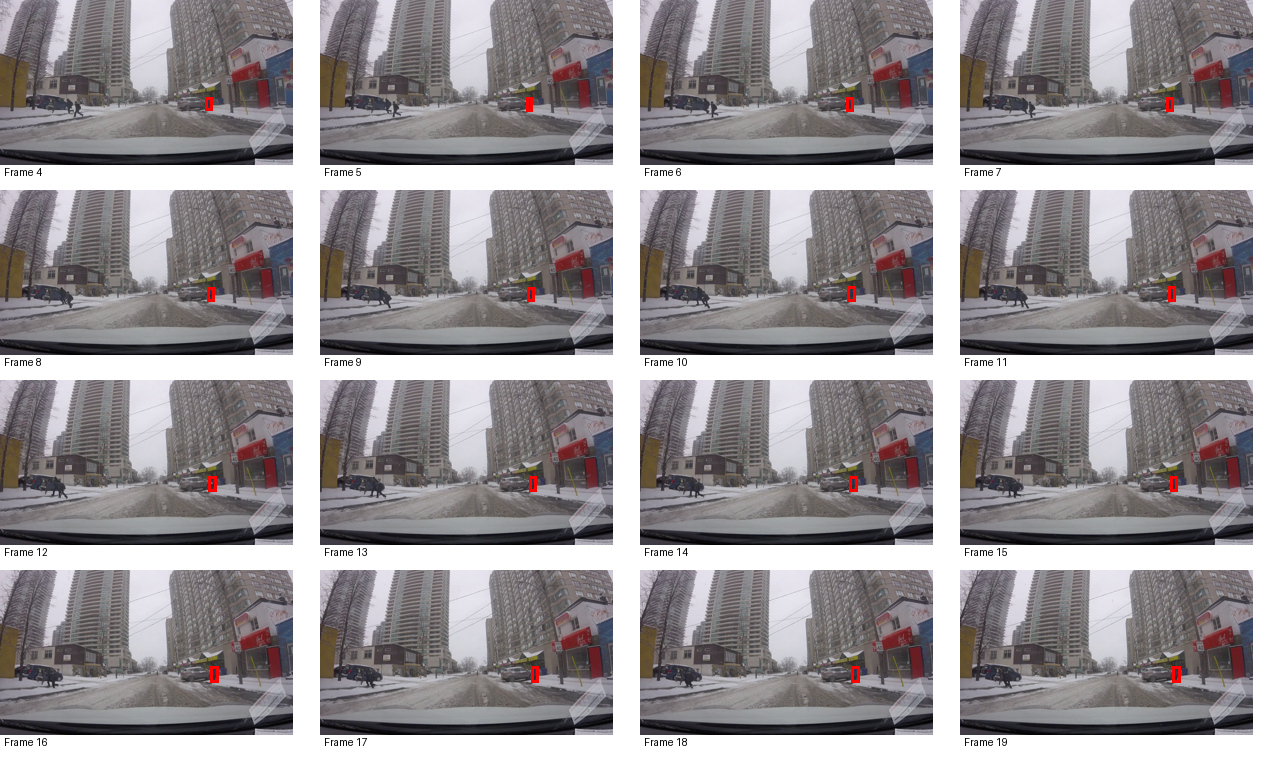

Negative example:


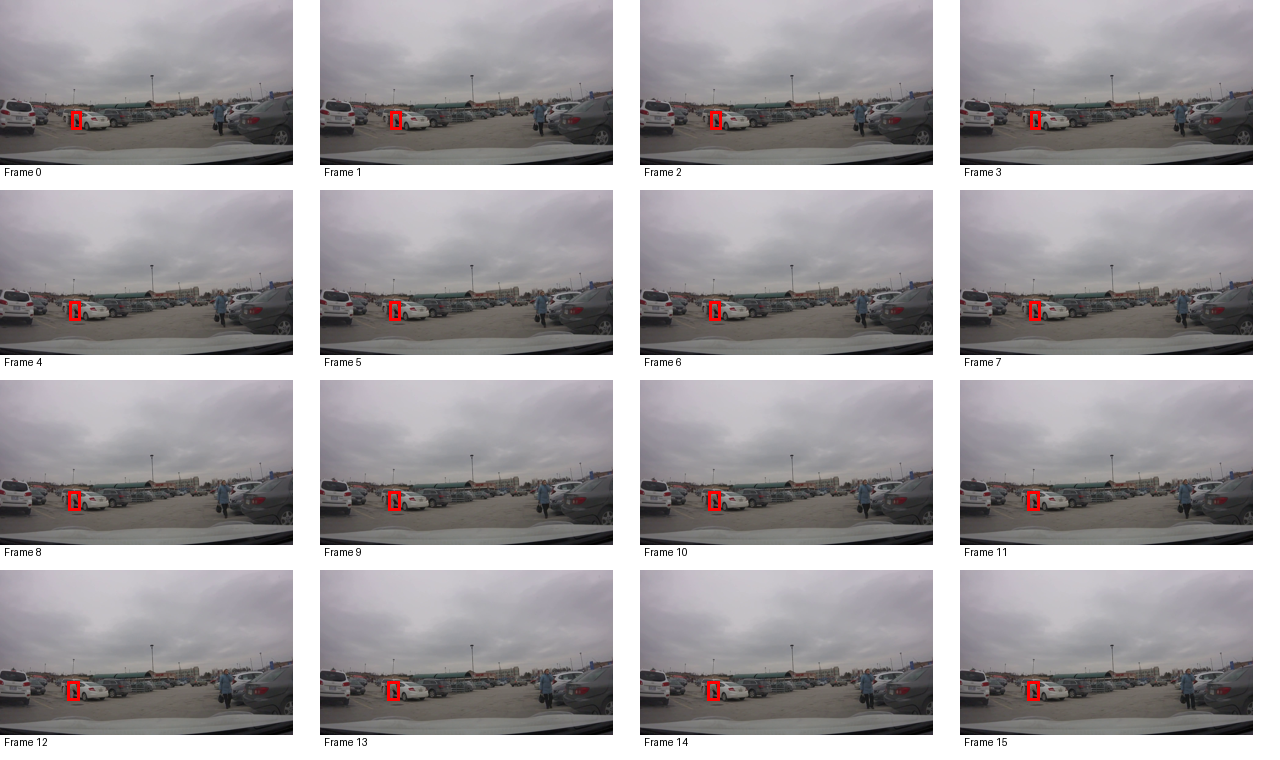

In [40]:

from IPython.display import display

positive_examples = [r for r in records
                     if r.get("split") == "train" and int(r["label"]) == 1]
negative_examples = [r for r in records
                     if r.get("split") == "train" and int(r["label"]) == 0]

print("Positive example:")
display(make_scene_contact_sheet(positive_examples[0], cell_size=320))

print("Negative example:")
display(make_scene_contact_sheet(negative_examples[0], cell_size=320))


In [41]:

from PIL import Image
import torch

def prepare_messages(record, image):
    user_prompt = make_user_prompt()

    messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text": SYSTEM_PROMPT}],
        },
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": user_prompt},
            ],
        },
        {
            "role": "assistant",
            "content": [{"type": "text", "text": str(int(record["label"]))}],
        },
    ]
    return messages

sample = balanced_train[0]
sample_image = make_scene_contact_sheet(sample, cell_size=320).convert("RGB")
sample_messages = prepare_messages(sample, sample_image)

sample_text = processor.apply_chat_template(
    sample_messages,
    tokenize=False,
    add_generation_prompt=False,
)

batch = processor(
    text=[sample_text],
    images=[sample_image],
    return_tensors="pt",
)

print("Image size:", sample_image.size)
print("Input IDs:", tuple(batch["input_ids"].shape))
print("Pixel values:", tuple(batch["pixel_values"].shape))
print("Image grid:", batch["image_grid_thw"])


Image size: (1280, 760)
Input IDs: (1, 637)
Pixel values: (1972, 1176)
Image grid: tensor([[ 1, 34, 58]])


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


In [ ]:

import os, math, random
import torch
from torch.optim import AdamW
from tqdm.auto import tqdm

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Start small. Increase to 2-3 epochs only after confirming learning.
EPOCHS = 2
LEARNING_RATE = 1e-4
MAX_TRAIN_EXAMPLES = len(balanced_train)

optimizer = AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
)

def encode_example(record):
    image = make_scene_contact_sheet(record, cell_size=320).convert("RGB")
    prompt_messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text": SYSTEM_PROMPT}],
        },
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": make_user_prompt()},
            ],
        },
    ]

    full_messages = prompt_messages + [
        {
            "role": "assistant",
            "content": [{"type": "text", "text": str(int(record["label"]))}],
        }
    ]

    prompt_text = processor.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    full_text = processor.apply_chat_template(
        full_messages,
        tokenize=False,
        add_generation_prompt=False,
    )

    prompt_inputs = processor(
        text=[prompt_text],
        images=[image],
        return_tensors="pt",
    )
    full_inputs = processor(
        text=[full_text],
        images=[image],
        return_tensors="pt",
    )

    labels = full_inputs["input_ids"].clone()
    prompt_length = prompt_inputs["input_ids"].shape[1]
    labels[:, :prompt_length] = -100
    labels[labels == processor.tokenizer.pad_token_id] = -100

    return full_inputs, labels

model.train()
global_step = 0
loss_history = []

for epoch in range(EPOCHS):
    random.shuffle(balanced_train)
    epoch_losses = []

    progress = tqdm(balanced_train[:MAX_TRAIN_EXAMPLES],
                    desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for record in progress:
        try:
            inputs, labels = encode_example(record)

            inputs = {
                k: v.to(model.device) if torch.is_tensor(v) else v
                for k, v in inputs.items()
            }
            labels = labels.to(model.device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(**inputs, labels=labels)
            loss = outputs.loss

            if not torch.isfinite(loss):
                print("Skipping non-finite loss at step", global_step)
                continue

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                max_norm=1.0,
            )
            optimizer.step()

            loss_value = float(loss.detach().cpu())
            epoch_losses.append(loss_value)
            loss_history.append(loss_value)
            global_step += 1
            progress.set_postfix(loss=f"{loss_value:.4f}")

        except torch.cuda.OutOfMemoryError:
            optimizer.zero_grad(set_to_none=True)
            torch.cuda.empty_cache()
            print("CUDA OOM: reduce image size or stop and revise batching.")
            raise

    mean_loss = sum(epoch_losses) / max(1, len(epoch_losses))
    print(f"Epoch {epoch + 1} mean loss: {mean_loss:.4f}")

    model.save_pretrained(os.path.join(OUTPUT_DIR, f"checkpoint_epoch_{epoch+1}"))
    processor.save_pretrained(OUTPUT_DIR)

model.save_pretrained(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)
print("Saved LoRA adapter to:", OUTPUT_DIR)


Epoch 1/2:   0%|          | 0/1094 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Skipping non-finite loss at step 6
Skipping non-finite loss at step 18
Skipping non-finite loss at step 19
Skipping non-finite loss at step 19
Skipping non-finite loss at step 19
Skipping non-finite loss at step 23
Skipping non-finite loss at step 25
Skipping non-finite loss at step 30
Skipping non-finite loss at step 30
Skipping non-finite loss at step 32
Skipping non-finite loss at step 32
Skipping non-finite loss at step 34
Skipping non-finite loss at step 42
Skipping non-finite loss at step 44
Skipping non-finite loss at step 55
Skipping non-finite loss at step 66
Skipping non-finite loss at step 68
Skipping non-finite loss at step 80
Skipping non-finite loss at step 87
Skipping non-finite loss at step 87
Skipping non-finite loss at step 94
Skipping non-finite loss at step 97
Skipping non-finite loss at step 97
Skipping non-finite loss at step 106
Skipping non-finite loss at step 115
Skipping non-finite loss at step 127
Skipping non-finite loss at step 132
Skipping non-finite loss 

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("LoRA training loss")
plt.grid(True)
plt.show()
